In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.utils.data import TensorDataset
from scipy.spatial.distance import pdist
import torch.nn.functional as F

from LJ13.score import ScoreNetwork
from LJ13.data import load_configs, center_configs, configs_to_tensor
from LJ13.sde import VESDE, estimate_sigma_max
from LJ13.train import train_model
from LJ13.sampling import predictor_corrector_sampler
from LJ13.analysis import lj_energy_batch, pairwise_distances_batch, effective_temperature

In [14]:
training_configs = load_configs("LJ13_configs.npy", n_atoms=13, n_dim=3)
training_configs_centered = center_configs(training_configs)
training_configs_centered_tensor = configs_to_tensor(training_configs_centered)
print(training_configs_centered_tensor.shape)

torch.Size([24994, 13, 3])


In [15]:
flat = training_configs_centered.reshape(training_configs_centered.shape[0], -1)
sigma_max = estimate_sigma_max(flat, n_subset=len(flat))
print("sigma_max:", sigma_max)

train_sde = VESDE(sigma_max=sigma_max, sigma_min=0.02)

sigma_max: 6.440439607553563


In [ ]:
model, loss_history = train_model(
    training_configs_centered_tensor,
    train_sde,
    num_epochs=600,
)

In [ ]:
model, loss_history = train_model()

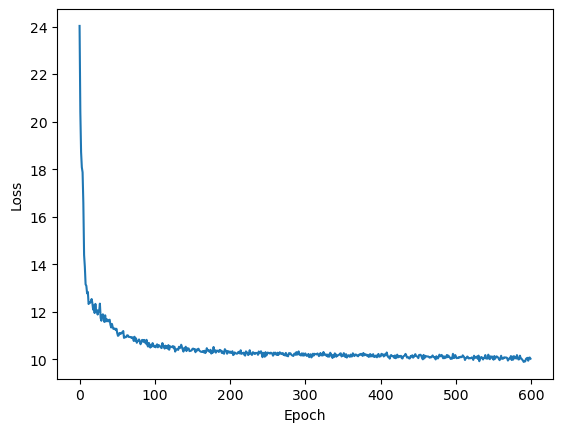

In [27]:
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

In [28]:
model = ScoreNetwork(hidden_dim=64, num_layers=3)

model.load_state_dict(torch.load("lj13_f_theta_strategy_1.pth"))

model.eval()

ScoreNetwork(
  (embedding): Linear(in_features=1, out_features=64, bias=True)
  (layers): ModuleList(
    (0-2): 3 x EGNNLayer(
      (message_mlp): MessageMLP(
        (net): Sequential(
          (0): Linear(in_features=130, out_features=64, bias=True)
          (1): SiLU()
          (2): Linear(in_features=64, out_features=64, bias=True)
          (3): SiLU()
        )
      )
      (feature_mlp): FeatureMLP(
        (net): Sequential(
          (0): Linear(in_features=128, out_features=64, bias=True)
          (1): SiLU()
          (2): Linear(in_features=64, out_features=64, bias=True)
        )
      )
      (coord_mlp): CoordMLP(
        (net): Sequential(
          (0): Linear(in_features=130, out_features=64, bias=True)
          (1): SiLU()
          (2): Linear(in_features=64, out_features=64, bias=True)
          (3): SiLU()
          (4): Linear(in_features=64, out_features=1, bias=True)
        )
      )
    )
  )
)

The loss is now roughly 12.2 (against a baseline of 36, since it is now in the COM-free subspace)
and it captures roughly 66% of the noise variance as opposed to 61% as in the previous model

It is quite clear that the model struggles to achieve the target at low sigma values, esp 0.01

In [29]:
sample_sde = VESDE(sigma_max=sigma_max, sigma_min=0.01)

samples = predictor_corrector_sampler(
    model,
    sample_sde,
    n_samples=1000,
    n_steps=1000,
    n_corrector=1,
    snr=0.16,
)

In [30]:
generated_energies = lj_energy_batch(samples).cpu().numpy()
training_energies = lj_energy_batch(training_configs_centered_tensor).cpu().numpy()

In [31]:
print("Training")
print(training_energies.min())
print(training_energies.max())
print(training_energies.mean())

print()

print("Generated")
print(generated_energies.min())
print(generated_energies.max())
print(generated_energies.mean())

Training
-43.767628
-40.267864
-42.52626

Generated
-43.398567
-39.62193
-42.327633


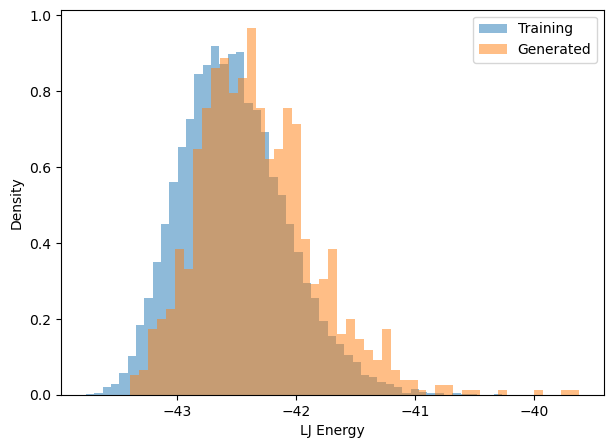

In [32]:
plt.figure(figsize=(7,5))

plt.hist(training_energies,
         bins=50,
         density=True,
         alpha=0.5,
         label="Training")

plt.hist(generated_energies,
         bins=50,
         density=True,
         alpha=0.5,
         label="Generated")

plt.xlabel("LJ Energy")
plt.ylabel("Density")
plt.legend()
plt.show()

In [33]:
mean_U_generated = np.mean(generated_energies)
print("Mean U generated:", mean_U_generated)

U_min = -44.3268

T_eff_generated = effective_temperature(mean_U_generated, U_min, n_dof=33)
print("Generated T_eff:", T_eff_generated)

Mean U generated: -42.327633
Generated T_eff: 0.12116172


The T_eff of the new model (with both 1/sigma parametrization and imposing a COM-free subspace) has reduced compared to the 0.1434 we measured for the previous model

In [35]:
x0 = training_configs_centered_tensor[:1000]

sigma_values = [
    0.02,
    0.01,
    0.005,
    0.003,
    0.001,
    0.0005,
    0.0003,
    0.0001
]

model.eval()

with torch.no_grad():

    for sigma_value in sigma_values:

        sigma = torch.tensor(sigma_value)

        noise = torch.randn_like(x0)

        noise = noise - noise.mean(dim=1,keepdim=True)

        x_noisy = x0 + sigma * noise

        log_sigma = torch.full((x0.shape[0], 1), np.log(sigma_value))

        f_pred = model(x_noisy, log_sigma)

        f_norm = torch.norm(f_pred.reshape(x0.shape[0], -1), dim=1)

        print(sigma_value, f_norm.mean().item())

0.02 3.15987229347229
0.01 2.301581621170044
0.005 2.889186143875122
0.003 4.787540435791016
0.001 10.543280601501465
0.0005 14.82371997833252
0.0003 18.037189483642578
0.0001 24.96288299560547


In [36]:
training_distances = pairwise_distances_batch(training_configs_centered_tensor)
generated_distances = pairwise_distances_batch(samples)

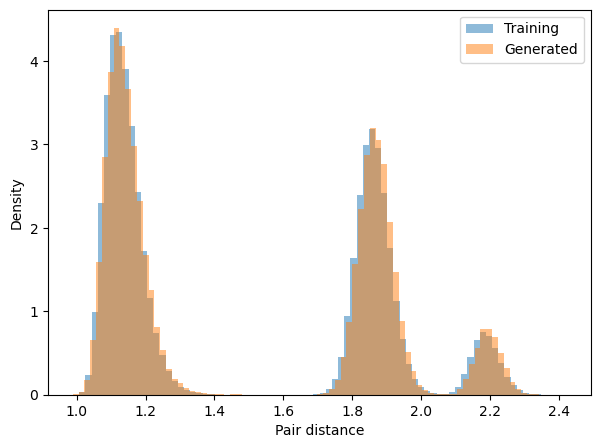

In [37]:
plt.figure(figsize=(7,5))

plt.hist(
    training_distances,
    bins=80,
    density=True,
    alpha=0.5,
    label="Training"
)

plt.hist(
    generated_distances,
    bins=80,
    density=True,
    alpha=0.5,
    label="Generated"
)

plt.xlabel("Pair distance")
plt.ylabel("Density")
plt.legend()

plt.show()